# Méthodes de Monte-Carlo et réduction de variance
### Application au pricing d'un call européen dans le modèle de Black-Scholes

## Présentation du projet

**Problématique.** On cherche à estimer le prix d'un call européen
$$C = \mathbb{E}\left[e^{-rT}(S_T - K)^+\right], \qquad S_T = S_0\, e^{(r-\sigma^2/2)T + \sigma\sqrt{T} Z},\quad Z\sim\mathcal{N}(0,1).$$
Dans ce modèle le prix exact est connu (formule de Black-Scholes), ce qui permet de **mesurer la qualité** des estimateurs Monte-Carlo. Pour des produits plus complexes (options exotiques, modèles sans formule fermée), la simulation devient la seule méthode disponible : il est donc essentiel de la rendre la plus précise possible pour un coût de calcul donné.

**Méthode de Monte-Carlo naïve.** On simule $N$ réalisations indépendantes du payoff actualisé et on en prend la moyenne empirique.

**Réduction de variance.** La précision de Monte-Carlo est en $\sigma/\sqrt{N}$ : diviser l'erreur par 10 coûte 100 fois plus de simulations. Plutôt que d'augmenter $N$, on cherche à **diminuer $\sigma$** :
- par les **variables antithétiques** ;
- par une **variable de contrôle**.

Paramètres de référence : $S_0 = 100,\ K = 100,\ r = 5\%,\ \sigma = 20\%,\ T = 1$ an.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from monte_carlo import (call_bs, call_mc, call_mc_antithetique, call_mc_controle,
                         n_minimum, ratios_reduction)

S0, K, r, sigma, T = 100, 100, 0.05, 0.2, 1
prix_exact = call_bs(S0, K, r, sigma, T)
print(f"Prix Black-Scholes exact : {prix_exact:.6f}")

Prix Black-Scholes exact : 10.450584


## 1. Méthode de Monte-Carlo naïve

### Loi forte des grands nombres (LFGN)
Soit $X = e^{-rT}(S_T-K)^+$ et $X_1,\dots,X_N$ i.i.d. de même loi que $X$, intégrables. Alors
$$\hat C_N = \frac{1}{N}\sum_{i=1}^N X_i \xrightarrow[N\to\infty]{p.s.} \mathbb{E}[X] = C.$$
L'estimateur est **sans biais** et **convergent**.

### Estimation de l'erreur via le TCL
Si $\sigma_X^2 = \mathrm{Var}(X) < \infty$ :
$$\sqrt{N}\,\frac{\hat C_N - C}{\sigma_X} \xrightarrow[N\to\infty]{\mathcal{L}} \mathcal{N}(0,1).$$
En remplaçant $\sigma_X$ par l'écart-type empirique $\hat\sigma_N$ (lemme de Slutsky), on obtient l'intervalle de confiance asymptotique à 95 % :
$$IC_{95\%} = \left[\hat C_N - 1{,}96\,\frac{\hat\sigma_N}{\sqrt N}\ ;\ \hat C_N + 1{,}96\,\frac{\hat\sigma_N}{\sqrt N}\right].$$

### Nombre minimum de simulations
Pour garantir une demi-largeur d'IC inférieure à $\varepsilon$ :
$$1{,}96\,\frac{\sigma_X}{\sqrt N}\le\varepsilon \iff N \ge \left(\frac{1{,}96\,\sigma_X}{\varepsilon}\right)^2.$$

In [2]:
# Code Python : Monte-Carlo naïf
prix, ic = call_mc(S0, K, r, sigma, T, N=1_000_000)
print(f"Prix MC naïf : {prix:.6f}")
print(f"IC 95 %      : [{ic[0]:.6f} ; {ic[1]:.6f}]  (largeur {ic[1]-ic[0]:.6f})")
print(f"Prix exact dans l'IC : {ic[0] <= prix_exact <= ic[1]}")

Prix MC naïf : 10.469705
IC 95 %      : [10.440823 ; 10.498588]  (largeur 0.057764)
Prix exact dans l'IC : True


In [3]:
# Estimation de sigma_X sur un échantillon pilote, puis N minimum
rng = np.random.default_rng(1)
Z = rng.standard_normal(100_000)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
sigma_X = (np.exp(-r * T) * np.maximum(ST - K, 0)).std(ddof=1)
print(f"Écart-type estimé du payoff : {sigma_X:.4f}")
for eps in [0.1, 0.05, 0.01]:
    print(f"Précision ±{eps:<5} -> N minimum = {n_minimum(sigma_X, eps):>12,}")

Écart-type estimé du payoff : 14.6800
Précision ±0.1   -> N minimum =       82,788
Précision ±0.05  -> N minimum =      331,150
Précision ±0.01  -> N minimum =    8,278,736


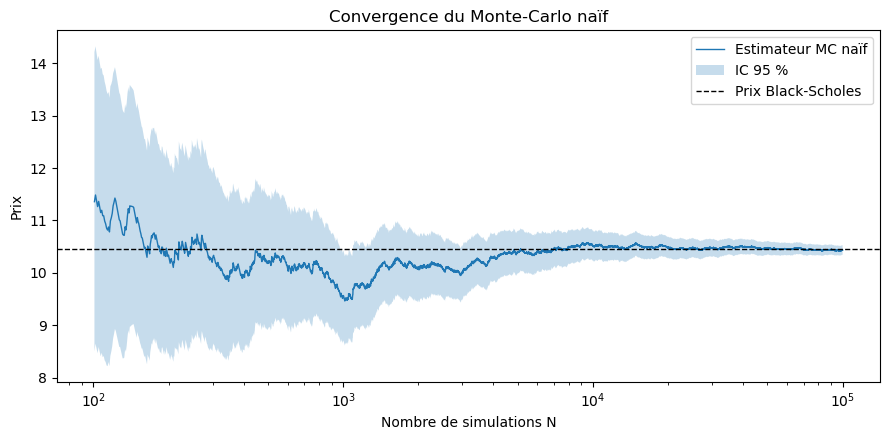

In [4]:
# Convergence de l'estimateur et de l'IC 95 % (illustration LFGN + TCL)
rng = np.random.default_rng(0)
N = 100_000
Z = rng.standard_normal(N)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
X = np.exp(-r * T) * np.maximum(ST - K, 0)
n = np.arange(1, N + 1)
moy = np.cumsum(X) / n
var = (np.cumsum(X**2) - n * moy**2) / np.maximum(n - 1, 1)
demi = 1.96 * np.sqrt(var / n)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(n[100:], moy[100:], lw=1, label="Estimateur MC naïf")
ax.fill_between(n[100:], (moy - demi)[100:], (moy + demi)[100:], alpha=0.25, label="IC 95 %")
ax.axhline(prix_exact, color="k", ls="--", lw=1, label="Prix Black-Scholes")
ax.set_xscale("log"); ax.set_xlabel("Nombre de simulations N"); ax.set_ylabel("Prix")
ax.set_title("Convergence du Monte-Carlo naïf"); ax.legend()
fig.tight_layout(); fig.savefig("figures/convergence_mc_naif.png", dpi=150); plt.show()

## 2. Réduction de variance via la méthode antithétique

### Présentation de la méthode
Si $Z\sim\mathcal N(0,1)$, alors $-Z$ a la même loi. On simule donc chaque trajectoire **par paire** :
$$S_T^{+} = S_0 e^{(r-\sigma^2/2)T+\sigma\sqrt T Z},\qquad S_T^{-} = S_0 e^{(r-\sigma^2/2)T-\sigma\sqrt T Z},$$
et on utilise $Y = \tfrac12\big(X^+ + X^-\big)$, qui vérifie $\mathbb E[Y] = C$ (estimateur toujours sans biais).

### Avantage par rapport au Monte-Carlo naïf
$$\mathrm{Var}(Y) = \frac{\sigma_X^2}{2}\,\big(1 + \rho(X^+,X^-)\big).$$
Une paire coûte 2 simulations ; à coût égal ($2N$ simulations), le naïf a une variance $\sigma_X^2/2N$ et l'antithétique $\sigma_X^2(1+\rho)/2N$. **Le gain est réel dès que $\rho < 0$**, ce qui est le cas ici car le payoff du call est une fonction **monotone** de $Z$. De plus, la méthode est gratuite : aucune information supplémentaire n'est requise, et on économise la moitié des tirages aléatoires.

In [5]:
# Code méthode antithétique (N = 500 000 paires = 1 000 000 de simulations)
prix_a, ic_a = call_mc_antithetique(S0, K, r, sigma, T, N=500_000)
print(f"Prix antithétique : {prix_a:.6f}")
print(f"IC 95 %           : [{ic_a[0]:.6f} ; {ic_a[1]:.6f}]  (largeur {ic_a[1]-ic_a[0]:.6f})")

Prix antithétique : 10.464331
IC 95 %           : [10.443925 ; 10.484738]  (largeur 0.040813)


### Puissance de la réduction en fonction du prix du sous-jacent
On fait varier $S_0$ à $K = 100$ fixé : **hors de la monnaie** (OTM, $S_0 < K$), **à la monnaie** (ATM, $S_0 = K$), **dans la monnaie** (ITM, $S_0 > K$). Le facteur de réduction est $\mathrm{Var}_{\text{naïf}} / \mathrm{Var}_{\text{méthode}}$ à coût égal.

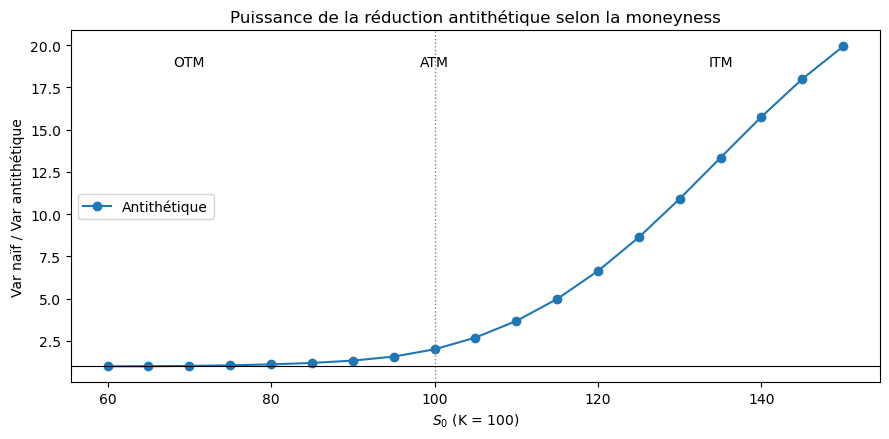

S0 =  70 : facteur de réduction = 1.02
S0 = 100 : facteur de réduction = 2.00
S0 = 130 : facteur de réduction = 10.91


In [6]:
S0_grille = np.arange(60, 151, 5)
ratios = np.array([ratios_reduction(s, K, r, sigma, T) for s in S0_grille])
ratio_anti, ratio_ctrl = ratios[:, 0], ratios[:, 1]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(S0_grille, ratio_anti, "o-", label="Antithétique")
ax.axvline(K, color="grey", ls=":", lw=1)
ax.axhline(1, color="k", lw=0.8)
ax.text(70, ax.get_ylim()[1] * 0.9, "OTM", ha="center"); ax.text(K, ax.get_ylim()[1] * 0.9, "ATM", ha="center")
ax.text(135, ax.get_ylim()[1] * 0.9, "ITM", ha="center")
ax.set_xlabel("$S_0$ (K = 100)"); ax.set_ylabel("Var naïf / Var antithétique")
ax.set_title("Puissance de la réduction antithétique selon la moneyness"); ax.legend(loc="center left")
fig.tight_layout(); fig.savefig("figures/reduction_antithetique.png", dpi=150); plt.show()

for s, ra in zip(S0_grille, ratio_anti):
    if s in (70, 100, 130): print(f"S0 = {s:>3} : facteur de réduction = {ra:.2f}")

**Interprétation.** Très **hors de la monnaie**, le payoff est nul pour la plupart des $Z$ et pour leurs antithétiques : $X^+$ et $X^-$ sont presque toujours simultanément nuls, la corrélation est proche de 0 et le gain est quasi nul (facteur ≈ 1). **À la monnaie**, le facteur est d'environ 2. **Dans la monnaie**, le payoff se comporte presque comme $S_T - K$, fonction quasi linéaire de $Z$ : $X^+$ et $X^-$ deviennent fortement anti-corrélés et le gain explose.

## 3. Réduction de variance via une variable de contrôle

### Présentation de la méthode
On utilise une variable $Y$ **corrélée à $X$** et dont l'**espérance est connue**. Ici $Y = e^{-rT}S_T$, avec $\mathbb E[Y] = S_0$ (actualisé du sous-jacent = martingale sous la probabilité risque-neutre). Pour tout $\beta$,
$$W_\beta = X - \beta\,(Y - S_0),\qquad \mathbb E[W_\beta] = C.$$

### Calcul de $\beta^*$
$$\mathrm{Var}(W_\beta) = \mathrm{Var}(X) - 2\beta\mathrm{Cov}(X,Y) + \beta^2\mathrm{Var}(Y).$$
C'est un polynôme du second degré en $\beta$, minimal en
$$\beta^* = \frac{\mathrm{Cov}(X,Y)}{\mathrm{Var}(Y)},\qquad \mathrm{Var}(W_{\beta^*}) = \mathrm{Var}(X)\,\big(1-\rho_{X,Y}^2\big).$$
En pratique $\beta^*$ est estimé sur les simulations par la covariance et la variance empiriques.

### Intérêt par rapport au Monte-Carlo naïf
La variance est **toujours** réduite (au pire inchangée si $\rho = 0$), pour un coût supplémentaire négligeable (une seule simulation de $S_T$ sert à $X$ et à $Y$). Plus $|\rho_{X,Y}|$ est proche de 1, plus le gain est fort : le facteur de réduction vaut $1/(1-\rho^2)$.

In [7]:
# Code Python : variable de contrôle
prix_c, ic_c = call_mc_controle(S0, K, r, sigma, T, N=1_000_000)
print(f"Prix variable de contrôle : {prix_c:.6f}")
print(f"IC 95 %                   : [{ic_c[0]:.6f} ; {ic_c[1]:.6f}]  (largeur {ic_c[1]-ic_c[0]:.6f})")

Prix variable de contrôle : 10.454543
IC 95 %                   : [10.443541 ; 10.465545]  (largeur 0.022004)


### Puissance de la réduction en fonction du sous-jacent (OTM, ATM, ITM)

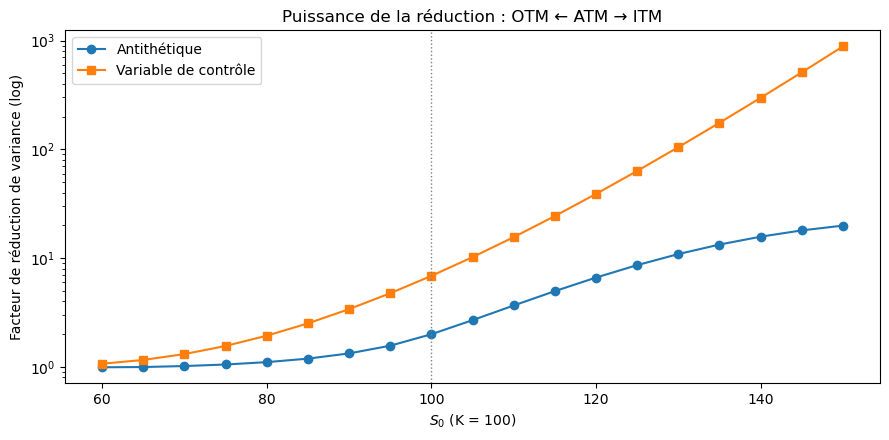

S0 =  70 : facteur de réduction = 1.31
S0 = 100 : facteur de réduction = 6.88
S0 = 130 : facteur de réduction = 104.78


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(S0_grille, ratio_anti, "o-", label="Antithétique")
ax.plot(S0_grille, ratio_ctrl, "s-", label="Variable de contrôle")
ax.axvline(K, color="grey", ls=":", lw=1)
ax.set_yscale("log")
ax.set_xlabel("$S_0$ (K = 100)"); ax.set_ylabel("Facteur de réduction de variance (log)")
ax.set_title("Puissance de la réduction : OTM ← ATM → ITM"); ax.legend()
fig.tight_layout(); fig.savefig("figures/reduction_controle.png", dpi=150); plt.show()

for s, rc in zip(S0_grille, ratio_ctrl):
    if s in (70, 100, 130): print(f"S0 = {s:>3} : facteur de réduction = {rc:.2f}")

**Interprétation.** Plus l'option est **dans la monnaie**, plus le call ressemble au sous-jacent ($X \approx Y - Ke^{-rT}$) : $\rho_{X,Y}\to 1$ et la variance est réduite d'un facteur de plusieurs dizaines, voire centaines. **Hors de la monnaie**, le payoff est le plus souvent nul alors que $S_T$ varie : la corrélation est faible et le gain se réduit. La variable de contrôle domine l'antithétique sur toute la grille.

## 4. Test de chaque méthode et comparaison des IC à 95 %
Les trois méthodes sont comparées **à coût égal** : $10^6$ évaluations de payoff (soit $5\cdot10^5$ paires pour l'antithétique).

In [9]:
resultats = {
    "MC naïf": call_mc(S0, K, r, sigma, T, N=1_000_000),
    "Antithétique": call_mc_antithetique(S0, K, r, sigma, T, N=500_000),
    "Variable de contrôle": call_mc_controle(S0, K, r, sigma, T, N=1_000_000),
}
larg_naif = resultats["MC naïf"][1][1] - resultats["MC naïf"][1][0]
print(f"{'Méthode':<22}{'Prix':>10}{'IC 95 %':>26}{'Largeur':>10}{'Gain':>8}  Contient BS")
for nom, (p, (a, b)) in resultats.items():
    print(f"{nom:<22}{p:>10.4f}   [{a:.4f} ; {b:.4f}]{b-a:>10.4f}{(larg_naif/(b-a))**2:>8.2f}  {a <= prix_exact <= b}")
print(f"\nPrix exact Black-Scholes : {prix_exact:.4f}")

Méthode                     Prix                   IC 95 %   Largeur    Gain  Contient BS
MC naïf                  10.4697   [10.4408 ; 10.4986]    0.0578    1.00  True
Antithétique             10.4643   [10.4439 ; 10.4847]    0.0408    2.00  True
Variable de contrôle     10.4545   [10.4435 ; 10.4655]    0.0220    6.89  True

Prix exact Black-Scholes : 10.4506


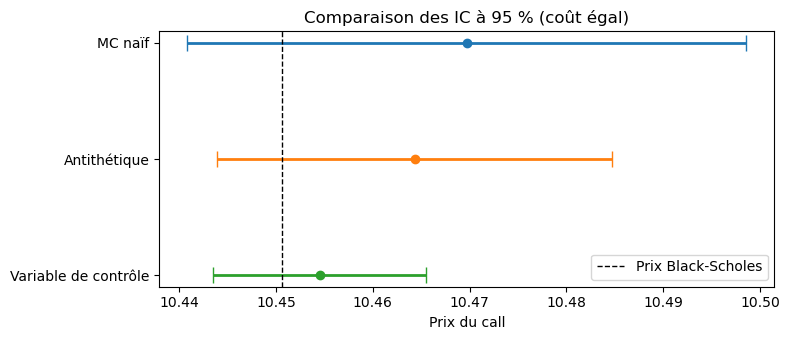

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, (nom, (p, (a, b))) in enumerate(resultats.items()):
    ax.errorbar(p, i, xerr=[[p - a], [b - p]], fmt="o", capsize=6, lw=2)
ax.axvline(prix_exact, color="k", ls="--", lw=1, label="Prix Black-Scholes")
ax.set_yticks(range(len(resultats))); ax.set_yticklabels(resultats.keys()); ax.invert_yaxis()
ax.set_xlabel("Prix du call"); ax.set_title("Comparaison des IC à 95 % (coût égal)"); ax.legend()
fig.tight_layout(); fig.savefig("figures/comparaison_ic95.png", dpi=150); plt.show()

## Conclusion
- Le Monte-Carlo naïf converge (LFGN) avec une erreur en $O(1/\sqrt N)$ quantifiée par le TCL.
- Les **variables antithétiques** réduisent la variance sans aucun coût supplémentaire, avec un gain qui croît quand l'option est dans la monnaie et devient négligeable hors de la monnaie.
- La **variable de contrôle** $e^{-rT}S_T$ est la plus efficace : facteur ≈ 7 à la monnaie, et jusqu'à plusieurs centaines dans la monnaie.
- À précision égale, réduire la variance d'un facteur $k$ revient à diviser par $k$ le nombre de simulations nécessaires.